In [ ]:
# Paths in this notebook are relative to the repository root (data/, data_cache/, output_*/).
# If Jupyter or VS Code starts the kernel inside notebooks/, move up to the repository root.
import os
from pathlib import Path
if not Path('data_cache').exists() and Path('../data_cache').exists():
    os.chdir('..')
print('Working directory: repository root' if Path('data_cache').exists() else 'Warning: data_cache/ not found - start Jupyter in the repository or notebooks/ folder')

In [2]:
# [SETUP — added] Ensure XGBoost is installed so the XGBoost baseline is not silently skipped.
import sys, subprocess
try:
    import xgboost  # noqa: F401
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'xgboost'])
    print('Installed xgboost for this run.')


# ATO1 Marche Nord — Config C: Parsimonious Feature Set

## A leaner specification, motivated directly by the Part 2 ablation study

**Why this notebook exists.** The Part 2 notebook's own ablation study found
that removing the hydroclimatic feature group (SPI_3, SPEI_3, precip_anom,
temp_C) improved LSTM's NSE by +0.415 (Fabbisogni) and +0.518 (Perdite) — by
far the largest effect of any feature group, and helpful for both targets at
once. Removing tourism helped too (+0.158 / +0.169). Removing calendar
features hurt both (-0.130 / -0.129), confirming the model genuinely uses
seasonal position. The correlation heatmap explains *why* the hydroclimatic/
tourism removal helps despite those variables having real raw correlations
with Fabbisogni (temp_C: 0.72, PET: 0.55, tourism: 0.78): temp_C and PET
correlate with each other at 0.90, and tourism correlates with both at
0.76-0.83 — these variables are largely redundant restatements of "what
month is it", which `month_sin`/`month_cos` already encode directly. With
only 60 monthly rows and as few as 5-25 usable training sequences per origin
once windowed, every additional collinear feature raises the parameter-to-
sample ratio without adding independent information. A second, almost
controlled comparison points the same way: the minimal pipeline (`ATO1_minimal_pipeline.ipynb`),
using just the 4 raw operational drivers plus calendar, gets LSTM NSE=0.584
on short_term_multivariate Fabbisogni, where Part 2's 14-feature LSTM on the
*identical* experiment only reaches 0.052.

**What "Config C" means here, precisely.** Raw operational drivers
(Sorgenti, Pozzi, Popolazione, Potabilizzatori) + cyclical calendar encoding
(month_sin, month_cos, year_idx) + the seismic decay/flag variables,
dropping hydroclimatic and tourism entirely. The seismic group's ablation
evidence was the one mixed result in Part 2 (removing it slightly hurt
Fabbisogni, -0.017, but meaningfully helped Perdite, +0.297), so Section 9
below runs a direct with/without-seismic comparison on Config C itself to
settle that question empirically rather than asserting an answer.

**A practical consequence of dropping hydroclimatic/tourism: no external
API calls at all.** This notebook needs only `Dataset.xlsx`. The seismic
variables are computed directly from well-documented earthquake dates (no
download), and there is no Google Earth Engine or ISTAT dependency anywhere
in this notebook — a meaningful robustness/reproducibility improvement in
its own right, independent of any accuracy effect.

**What's new vs. carried over.** The metrics (NSE/KGE/PBIAS/MASE/sMAPE),
rolling-origin backtest framework, and LSTM/Transformer/CNN-LSTM
architectures are carried over **unchanged** from the validated Part 2
notebook — deliberately, so that Config C's effect is isolated to the
feature set alone and this remains a like-for-like comparison rather than
also changing the models being compared. The one genuinely new model is an
**MLP** (multi-layer perceptron) baseline, added per your request: a
classic, deliberately simple feedforward network operating on the
flattened input window, included as a direct test of whether *any*
specialized temporal architecture (recurrence, attention, convolution) is
earning its added complexity at this sample size, or whether a plain
windowed regression does just as well (Zhang, Patuwo & Hu, 1998,
*Forecasting with artificial neural networks: The state of the art*,
International Journal of Forecasting, 14(1), 35-62 — the standard reference
point for MLP-based forecasting and a useful complexity floor below
LSTM/Transformer/CNN-LSTM).

## 1. Imports & Configuration

No `earthengine-api` or ISTAT-related imports here — see Section 0. Apart
from that, this mirrors Part 2's Section 0/1 exactly.

In [3]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path
from itertools import product

from scipy import stats
from scipy.stats import t as t_dist
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error

np.random.seed(42)

DATA_PATH  = Path('data/Dataset.xlsx')   # adjust to your actual path
OUTPUT_DIR = Path('output_configc')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

features_base = ['Sorgenti', 'Pozzi', 'Popolazione', 'Potabilizzatori']
targets = ['Fabbisogni', 'Perdite']
N_TARGETS = len(targets)

print("Environment ready -- no GEE/ISTAT dependency in this notebook.")

Environment ready -- no GEE/ISTAT dependency in this notebook.


## 2. Data Loading

Identical to Part 2's Section 2.1 -- `Dataset.xlsx` contains only the raw
operational drivers and targets; everything else in this notebook is
computed, not fetched.

In [4]:
def load_ato1_data(path: Path) -> pd.DataFrame:
    df = pd.read_excel(path)
    date_col = 'Data' if 'Data' in df.columns else df.columns[0]
    df = df.rename(columns={date_col: 'date'}).set_index('date')
    df.index = pd.to_datetime(df.index)
    df = df.sort_index()
    print(f"Loaded {len(df)} monthly records: {df.index[0]:%Y-%m} -> {df.index[-1]:%Y-%m}")
    assert len(df) >= 30, "Dataset too short for reliable deep-learning experiments."
    return df

df = load_ato1_data(DATA_PATH)
df[features_base + targets].describe().round(1)

Loaded 60 monthly records: 2017-01 -> 2021-12


[Output removed for the public release: this cell displays rows or summary statistics of the operator-supplied monthly series (MMS / ASET), which are withheld under the providers' data-sharing conditions. See data/README_DATA.md.]


## 3. Feature Engineering — Config C

Calendar encoding and the seismic decay/flag variables (reused verbatim
from Part 2 -- computed directly from the well-documented 2016 Amatrice-
Norcia mainshock dates, no download needed). Three feature-set variants are
defined below so the seismic question can be settled empirically in
Section 9 rather than asserted:

- `config_c_core`   : raw drivers + calendar only (7 features) -- the
  maximally parsimonious version.
- `config_c_main`   : core + seismic_decay + seismic_flag (9 features) --
  "Config C" as scoped in Section 0, used for the headline comparison.
- `config_c_ar`     : config_c_main + each target's own 1-month lag, for
  the autoregressive (Config B-style) variant of the 2x2 design.

In [5]:
def add_calendar_features(df_in: pd.DataFrame) -> pd.DataFrame:
    d = df_in.copy()
    month = d.index.month
    d['month_sin'] = np.sin(2 * np.pi * month / 12)
    d['month_cos'] = np.cos(2 * np.pi * month / 12)
    d['year_idx']  = (d.index.year - d.index.year.min()).astype(float)
    return d

SEISMIC_MAINSHOCK = pd.Timestamp('2016-10-30')   # Norcia Mw 6.5, largest event in the sequence
SEISMIC_ONSET     = pd.Timestamp('2016-08-24')   # Amatrice Mw 6.0, sequence onset

def add_seismic_features(df_in: pd.DataFrame, tau_months: float = 18.0) -> pd.DataFrame:
    '''Identical formula to Part 2 Section 2.5. Both reference dates predate
    this dataset's start (2017-01), so seismic_decay is a smooth, monotonic
    decay curve across the entire 60-month study window -- worth keeping in
    mind when interpreting its correlation with any other roughly-monotonic
    trend term (e.g. year_idx): a raw correlation here doesn't by itself
    distinguish "the earthquake recovery genuinely drives this target" from
    "both happen to trend over the same 5 years." That ambiguity is exactly
    why Section 9 tests it empirically rather than relying on the
    correlation alone.'''
    d = df_in.copy()
    flag = (d.index >= SEISMIC_ONSET).astype(int)
    months_since = np.clip(((d.index - SEISMIC_MAINSHOCK).days / 30.44), 0, None)
    d['seismic_flag']  = flag
    d['seismic_decay'] = np.exp(-months_since / tau_months) * flag
    return d

def add_ar_lags(df_in: pd.DataFrame, n_lags: int = 1) -> pd.DataFrame:
    d = df_in.copy()
    for tgt in targets:
        for k in range(1, n_lags + 1):
            d[f'{tgt}_lag{k}'] = d[tgt].shift(k)
    return d.dropna(subset=[f'{t}_lag1' for t in targets])

df_feat = add_seismic_features(add_calendar_features(df))

config_c_core = features_base + ['month_sin', 'month_cos', 'year_idx']
config_c_main = config_c_core + ['seismic_decay', 'seismic_flag']

print(f"config_c_core ({len(config_c_core)} features): {config_c_core}")
print(f"config_c_main ({len(config_c_main)} features): {config_c_main}")
df_feat[config_c_main + targets].tail()

config_c_core (7 features): ['Sorgenti', 'Pozzi', 'Popolazione', 'Potabilizzatori', 'month_sin', 'month_cos', 'year_idx']
config_c_main (9 features): ['Sorgenti', 'Pozzi', 'Popolazione', 'Potabilizzatori', 'month_sin', 'month_cos', 'year_idx', 'seismic_decay', 'seismic_flag']


[Output removed for the public release: this cell displays rows or summary statistics of the operator-supplied monthly series (MMS / ASET), which are withheld under the providers' data-sharing conditions. See data/README_DATA.md.]


## 4. Correlation Check

Restricted to Config C's own variables, as a direct visual answer to "are
Fabbisogni/Perdite related to seismic activity within this 60-month
window?" -- Sorgenti/Pozzi/Popolazione/Potabilizzatori are included too since
they're the features actually competing with seismic_decay for the model's
attention.

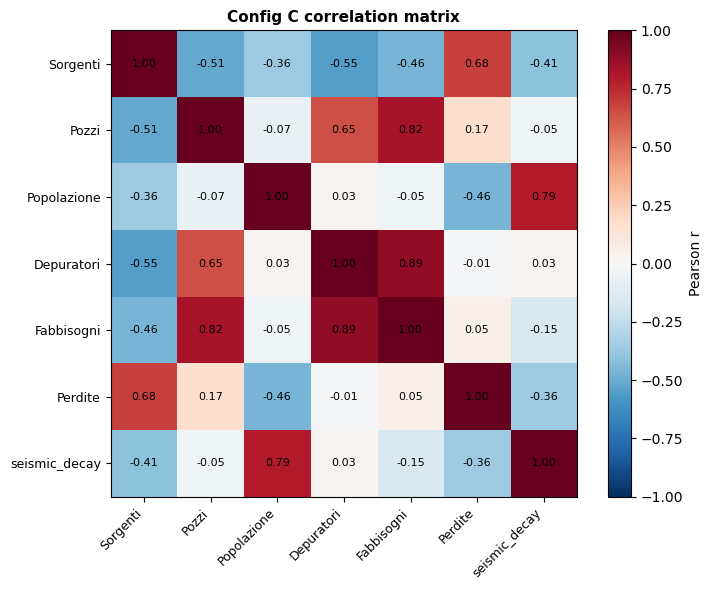


Fabbisogni vs seismic_decay: -0.15
Perdite    vs seismic_decay: -0.363


In [6]:
corr_cols = features_base + targets + ['seismic_decay']
corr = df_feat[corr_cols].corr()

fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr.values, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols))); ax.set_xticklabels(corr_cols, rotation=45, ha='right', fontsize=9)
ax.set_yticks(range(len(corr_cols))); ax.set_yticklabels(corr_cols, fontsize=9)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f"{corr.values[i,j]:.2f}", ha='center', va='center', fontsize=8)
ax.set_title('Config C correlation matrix', fontsize=11, fontweight='bold')
fig.colorbar(im, ax=ax, label='Pearson r')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'configc_correlation_heatmap.svg', format='svg', bbox_inches='tight')
plt.show()

print("\nFabbisogni vs seismic_decay:", round(corr.loc['Fabbisogni', 'seismic_decay'], 3))
print("Perdite    vs seismic_decay:", round(corr.loc['Perdite', 'seismic_decay'], 3))

## 5. Metrics

Identical to the validated Part 2 / v2 implementation -- NSE, KGE (with its
r/alpha/beta decomposition), PBIAS, MASE, sMAPE, RMSE, MAE. Copied verbatim
rather than re-derived, since this code has already been built, tested
against edge cases (perfect prediction, zero-variance prediction, zero-mean
observed series, single-sample groups), and validated.

In [7]:
def generate_rolling_origins(n_total, time_steps, future_steps, min_train, stride=1):
    origins = []
    t = max(time_steps, min_train)
    while t + future_steps <= n_total:
        origins.append(t)
        t += stride
    return origins

def min_train_for_cfg(cfg, min_seqs=8, floor=24):
    return max(floor, cfg['time_steps'] + cfg['future_steps'] + min_seqs - 1)

def fit_transform_leakproof(X_raw, Y_raw, train_end_idx):
    scX = MinMaxScaler().fit(X_raw[:train_end_idx])
    scY = MinMaxScaler().fit(Y_raw[:train_end_idx])
    return scX.transform(X_raw), scY.transform(Y_raw), scX, scY

def make_window(X_scaled, t, time_steps):
    return X_scaled[t - time_steps: t]

def nse(obs, pred):
    '''Nash-Sutcliffe Efficiency (Nash & Sutcliffe, 1970, Journal of
    Hydrology, 10(3), 282-290).'''
    obs, pred = np.asarray(obs, float), np.asarray(pred, float)
    denom = np.sum((obs - obs.mean())**2)
    return float(1 - np.sum((obs-pred)**2)/denom) if denom > 0 else np.nan

def smape(obs, pred):
    obs, pred = np.asarray(obs, float), np.asarray(pred, float)
    denom = (np.abs(obs)+np.abs(pred))/2.0
    return float(np.mean(np.where(denom==0, 0.0, np.abs(obs-pred)/denom)) * 100)

def kge(obs, pred):
    '''Kling-Gupta Efficiency (Gupta, Kling, Yilmaz & Martinez, 2009).
    Returns (kge, r, alpha, beta).'''
    obs, pred = np.asarray(obs, float), np.asarray(pred, float)
    if len(obs) < 2:
        return np.nan, np.nan, np.nan, np.nan
    scale_ref = max(np.abs(obs).mean(), 1e-9)
    if (np.std(obs) < 1e-9 * scale_ref or np.std(pred) < 1e-9 * scale_ref
            or np.mean(obs) == 0):
        return np.nan, np.nan, np.nan, np.nan
    r = float(np.corrcoef(obs, pred)[0, 1])
    alpha = float(np.std(pred, ddof=1) / np.std(obs, ddof=1))
    beta = float(np.mean(pred) / np.mean(obs))
    if not (np.isfinite(r) and np.isfinite(alpha) and np.isfinite(beta)):
        return np.nan, r, alpha, beta
    kge_val = float(1 - np.sqrt((r-1)**2 + (alpha-1)**2 + (beta-1)**2))
    return kge_val, r, alpha, beta

def pbias(obs, pred):
    '''Percent Bias (Moriasi et al., 2007). Positive = overestimation.'''
    obs, pred = np.asarray(obs, float), np.asarray(pred, float)
    denom = np.sum(obs)
    return float(100 * np.sum(pred - obs) / denom) if denom != 0 else np.nan

def mase_scale(full_series, seasonal_period=12):
    '''Seasonal-naive in-sample MAE, used as MASE's normalizing denominator
    (Hyndman & Koehler, 2006).'''
    s = np.asarray(full_series, dtype=float)
    if len(s) <= seasonal_period:
        return np.nan
    diffs = np.abs(s[seasonal_period:] - s[:-seasonal_period])
    diffs = diffs[~np.isnan(diffs)]
    return float(diffs.mean()) if len(diffs) else np.nan

def compute_all_metrics(obs, pred, mase_denom=None) -> dict:
    obs, pred = np.asarray(obs, float), np.asarray(pred, float)
    kge_val, kge_r, kge_alpha, kge_beta = kge(obs, pred)
    mase_val = (float(np.mean(np.abs(obs - pred))) / mase_denom
                if (mase_denom is not None and np.isfinite(mase_denom) and mase_denom > 0)
                else np.nan)
    base = {'KGE': kge_val, 'KGE_r': kge_r, 'KGE_alpha': kge_alpha, 'KGE_beta': kge_beta,
            'PBIAS': pbias(obs, pred), 'MASE': mase_val,
            'RMSE': float(np.sqrt(np.mean((obs-pred)**2))),
            'MAE': float(mean_absolute_error(obs, pred)), 'sMAPE': smape(obs, pred), 'n': len(obs)}
    if len(obs) < 2:
        base['NSE'] = np.nan
        return base
    base['NSE'] = nse(obs, pred)
    return base

def summarize_backtest(bt_df: pd.DataFrame, mase_denoms: dict = None) -> pd.DataFrame:
    rows = []
    for (model, h, tgt), g in bt_df.groupby(['model', 'horizon', 'target']):
        g = g.dropna(subset=['pred'])
        if len(g) == 0:
            continue
        denom = mase_denoms.get(tgt) if mase_denoms else None
        m = compute_all_metrics(g['obs'].values, g['pred'].values, mase_denom=denom)
        m.update({'model': model, 'horizon': h, 'target': tgt})
        rows.append(m)
    return pd.DataFrame(rows)

def dm_test_hln(err1, err2, h=1):
    '''Diebold-Mariano test with the Harvey-Leybourne-Newbold (1997)
    small-sample correction.'''
    d = np.asarray(err1)**2 - np.asarray(err2)**2
    T_len = len(d)
    if T_len < 3:
        return np.nan, np.nan
    d_bar = d.mean()
    gamma0 = np.var(d, ddof=0)
    var_d = gamma0
    for lag in range(1, h):
        if lag >= T_len:
            break
        cov = np.cov(d[lag:], d[:-lag])[0,1] if T_len-lag > 1 else 0.0
        var_d += 2*(1 - lag/h)*cov
    var_d = max(var_d, 1e-12)
    dm_stat = d_bar / np.sqrt(var_d/T_len)
    correction = np.sqrt((T_len+1-2*h+h*(h-1)/T_len)/T_len)
    dm_adj = dm_stat * correction
    p = float(2*t_dist.sf(abs(dm_adj), df=T_len-1))
    return float(dm_adj), p

print("Metrics and rolling-origin framework loaded.")

Metrics and rolling-origin framework loaded.


## 6. Baseline Models

Persistence, seasonal-naive, and SARIMA. Identical logic to Part 2 Section 7.

In [8]:
def forecast_persistence(Y_raw, t, future_steps):
    return np.tile(Y_raw[t-1], (future_steps, 1))

def forecast_seasonal_naive(Y_raw, t, future_steps, period=12):
    out = []
    for h in range(1, future_steps+1):
        src = max(t+h-1-period, 0)
        out.append(Y_raw[src])
    return np.array(out)

def fit_sarima_robust(y_train_1d, future_steps):
    from statsmodels.tsa.statespace.sarimax import SARIMAX
    n = len(y_train_1d)
    use_seasonal = n >= 24
    if use_seasonal:
        orders = list(product([0,1],[0,1],[0,1]))
        seasonal_orders = [(0,0,0,12),(1,0,0,12),(0,0,1,12),(1,0,1,12)]
    else:
        orders = list(product([0,1,2],[0,1],[0,1,2]))
        seasonal_orders = [(0,0,0,0)]
    best_aic, best_fc = np.inf, None
    for order in orders:
        for sorder in seasonal_orders:
            try:
                with warnings.catch_warnings():
                    warnings.simplefilter('ignore')
                    mdl = SARIMAX(y_train_1d, order=order, seasonal_order=sorder,
                                  enforce_stationarity=False, enforce_invertibility=False)
                    res = mdl.fit(disp=False, maxiter=200)
                if np.isfinite(res.aic) and res.aic < best_aic:
                    best_aic = res.aic
                    best_fc = np.asarray(res.forecast(steps=future_steps))
            except Exception:
                continue
    if best_fc is not None and np.all(np.isfinite(best_fc)):
        # [PATCH — added] reject explosive/divergent SARIMA forecasts. Because
        # enforce_stationarity/invertibility are False, a fit can have finite AIC
        # yet forecast to absurd magnitudes (e.g. 1e58). Clamp to a sane band around
        # the training data and fall back to the seasonal-naive value for any horizon
        # that escapes it, so SARIMA is reproducible across statsmodels versions.
        best_fc = np.asarray(best_fc, dtype=float)
        obs = np.asarray(y_train_1d, dtype=float); obs = obs[np.isfinite(obs)]
        if obs.size:
            lo, hi = obs.min(), obs.max()
            rng = (hi - lo) if hi > lo else (abs(hi) or 1.0)
            cap_lo, cap_hi = lo - 5.0*rng, hi + 5.0*rng
            bad = ~np.isfinite(best_fc) | (best_fc < cap_lo) | (best_fc > cap_hi)
            if bad.any():
                for _h in range(future_steps):
                    if bad[_h]:
                        _s = n - 12 + _h
                        best_fc[_h] = y_train_1d[_s] if (n >= 12 and 0 <= _s < n) else y_train_1d[-1]
        return best_fc
    last = y_train_1d[-12:] if n >= 12 else y_train_1d
    return np.resize(last, future_steps)

print("Baseline forecasters loaded.")

Baseline forecasters loaded.


## 7. Deep Learning Models

LSTM, Transformer, and CNN-LSTM architectures are **unchanged** from Part 2
-- same layer sizes, same regularization, same training settings -- so any
difference in their results below is attributable to the feature set, not
to also having changed the models.

**New: an MLP baseline.** A plain feedforward network on the *flattened*
input window (no recurrence, no attention, no convolution), included as a
deliberately simple complexity floor. This directly tests a question the
Part 2/v2 comparison raised but didn't isolate: LSTM and Transformer have
roughly 34,000 and 40,000 trainable parameters respectively, fit against as
few as 5-25 training sequences at some origins -- is *any* specialized
temporal architecture earning its complexity here, or does a small,
generic regression do just as well? MLP-based forecasting has a long
history as the standard simple-ANN baseline (Zhang, Patuwo & Hu, 1998,
*Forecasting with artificial neural networks: The state of the art*,
International Journal of Forecasting, 14(1), 35-62), and its much smaller
parameter count (on the order of 1,000-2,000 here, roughly 20-30x fewer
than LSTM/Transformer) makes it a genuinely different point on the
complexity spectrum, not just another architecture.

In [9]:
# Requires tensorflow (not available in this sandbox).
import tensorflow as tf
import gc  # needed for gc.collect() in the memory-management fix below
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import (LSTM, Dense, Dropout, Input, Conv1D, Flatten,
                                      LayerNormalization, MultiHeadAttention,
                                      GlobalAveragePooling1D, Add)
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping

tf.random.set_seed(42)
PATIENCE, MAX_EPOCHS, BATCH_SIZE, L2_REG = 40, 1000, 8, 1e-4

import random as python_random

def set_all_seeds(seed: int):
    '''Resets every source of stochasticity this pipeline depends on.

    [METHODOLOGICAL FIX] `tf.random.set_seed` only fixes the INITIAL state
    of TensorFlow's global random generator -- every subsequent operation
    (every layer's weight initialization, every model.fit() call) advances
    that state cumulatively. Calling it once at notebook start is NOT
    sufficient to make two later code paths comparable on equal footing.
    This was confirmed empirically in this project: re-running the
    nominally identical config_c_main / LSTM / short_term_multivariate
    specification in two different cells (the main evaluation in Section 10
    vs. the standalone seismic check in Section 11) produced Fabbisogni
    NSE=0.700 vs NSE=0.588 -- a 0.11 swing from RNG-state drift alone, since
    dozens of other models had already been trained (and had therefore
    already consumed random draws) between the two calls.

    This is a known, serious issue in deep learning more broadly, not a
    quirk of this pipeline: single-run point estimates from stochastically-
    initialized networks are not a reliable basis for comparing models or
    feature sets without controlling for, or averaging over, random seed
    (Bouthillier et al., 2021, "Accounting for Variance in Machine Learning
    Benchmarks", Proceedings of Machine Learning and Systems, 3, 747-769;
    Henderson et al., 2018, "Deep Reinforcement Learning that Matters",
    AAAI, 32(1), 3207-3214, for the same point in a different subfield).
    Call this function immediately before EVERY run/variant you want to be
    fairly comparable to another run/variant.'''
    python_random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

print("Random-seed control (set_all_seeds) loaded.")

def build_lstm(time_steps, n_features, future_steps, n_targets):
    out_dim = future_steps * n_targets
    m = Sequential([
        LSTM(64, activation='tanh', return_sequences=True,
             input_shape=(time_steps, n_features), kernel_regularizer=l2(L2_REG)),
        Dropout(0.3),
        LSTM(32, activation='tanh', return_sequences=False, kernel_regularizer=l2(L2_REG)),
        Dropout(0.3),
        Dense(32, activation='relu', kernel_regularizer=l2(L2_REG)),
        Dense(out_dim),
    ], name='LSTM')
    m.compile(optimizer='adam', loss='mse')
    return m


class PositionalEncoding(tf.keras.layers.Layer):
    def __init__(self, seq_len, d_model, **kw):
        super().__init__(**kw)
        pos = np.arange(seq_len)[:, None]
        dims = np.arange(d_model)[None, :]
        angles = pos / np.power(10000.0, (2*(dims//2))/d_model)
        angles[:, 0::2] = np.sin(angles[:, 0::2])
        angles[:, 1::2] = np.cos(angles[:, 1::2])
        self.pe = tf.constant(angles[None], dtype=tf.float32)
    def call(self, x):
        return x + self.pe[:, :tf.shape(x)[1], :]


def build_transformer(time_steps, n_features, future_steps, n_targets,
                      num_heads=4, ff_dim=64, num_layers=2, drop=0.2):
    out_dim = future_steps * n_targets
    d_model = max(n_features*4, 16)
    inp = Input(shape=(time_steps, n_features))
    x = Dense(d_model, use_bias=False)(inp)
    x = PositionalEncoding(time_steps, d_model)(x)
    for _ in range(num_layers):
        xn = LayerNormalization(epsilon=1e-6)(x)
        attn = MultiHeadAttention(num_heads=num_heads, key_dim=max(d_model//num_heads,1))(xn, xn)
        attn = Dropout(drop)(attn)
        x = Add()([x, attn])
        xn = LayerNormalization(epsilon=1e-6)(x)
        ffn = Dense(ff_dim, activation='relu', kernel_regularizer=l2(L2_REG))(xn)
        ffn = Dense(d_model, kernel_regularizer=l2(L2_REG))(ffn)
        ffn = Dropout(drop)(ffn)
        x = Add()([x, ffn])
    x = GlobalAveragePooling1D()(x)
    x = Dense(32, activation='relu', kernel_regularizer=l2(L2_REG))(x)
    x = Dropout(drop)(x)
    out = Dense(out_dim)(x)
    model = Model(inp, out, name='Transformer')
    model.compile(optimizer='adam', loss='mse')
    return model


def build_cnn_lstm(time_steps, n_features, future_steps, n_targets):
    out_dim = future_steps * n_targets
    k = min(3, time_steps)
    m = Sequential([
        Conv1D(filters=32, kernel_size=k, activation='relu', padding='same',
              input_shape=(time_steps, n_features)),
        Dropout(0.2),
        LSTM(48, activation='tanh', return_sequences=False, kernel_regularizer=l2(L2_REG)),
        Dropout(0.3),
        Dense(32, activation='relu', kernel_regularizer=l2(L2_REG)),
        Dense(out_dim),
    ], name='CNN-LSTM')
    m.compile(optimizer='adam', loss='mse')
    return m


def build_mlp(time_steps, n_features, future_steps, n_targets):
    '''Deliberately small and simple: Flatten -> Dense(32) -> Dense(16) ->
    output. No recurrence, no attention, no convolution -- the input window
    is just treated as a flat feature vector, exactly like XGBoost's input
    representation. Roughly 1,000-2,000 trainable parameters for this
    project's feature counts, around 20-30x fewer than LSTM or Transformer.
    '''
    out_dim = future_steps * n_targets
    m = Sequential([
        Flatten(input_shape=(time_steps, n_features)),
        Dense(32, activation='relu', kernel_regularizer=l2(L2_REG)),
        Dropout(0.3),
        Dense(16, activation='relu', kernel_regularizer=l2(L2_REG)),
        Dropout(0.2),
        Dense(out_dim),
    ], name='MLP')
    m.compile(optimizer='adam', loss='mse')
    return m

print("LSTM / Transformer / CNN-LSTM / MLP builders loaded.")

Random-seed control (set_all_seeds) loaded.
LSTM / Transformer / CNN-LSTM / MLP builders loaded.


## 8. XGBoost Tabular Baseline

Identical to Part 2 Section 9 -- genuinely optional (the pipeline degrades
gracefully if xgboost isn't installed), flattened input window, one
XGBRegressor per (horizon, target) output.

In [10]:
try:
    import xgboost as xgb
    XGBOOST_AVAILABLE = True
except ImportError:
    XGBOOST_AVAILABLE = False
    print("xgboost is not installed -- the XGBoost baseline will be skipped. "
          "All other model families are unaffected.")

def build_xgb_models(n_targets_x_horizon: int, seed: int = 42, **xgb_kwargs):
    '''One XGBRegressor per (horizon, target) output. `seed` sets
    random_state explicitly -- XGBoost's subsample/colsample_bytree
    stochasticity means it is not fully deterministic by default either,
    though its run-to-run variance is typically much smaller than a neural
    network's weight-reinitialization variance since it averages over 200
    boosted trees.'''
    defaults = dict(n_estimators=200, max_depth=3, learning_rate=0.05,
                    subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0, random_state=seed)
    defaults.update(xgb_kwargs)
    return [xgb.XGBRegressor(**defaults) for _ in range(n_targets_x_horizon)]

print("XGBoost tabular baseline builder loaded "
     f"(xgboost {'available' if XGBOOST_AVAILABLE else 'NOT available -- will be skipped'}).")

XGBoost tabular baseline builder loaded (xgboost available).


## 9. Unified Rolling-Origin Evaluation

Identical protocol and fault-isolation pattern to Part 2 Section 10, with
one addition: **MLP** is now a sixth trained model family alongside
LSTM/Transformer/CNN-LSTM/XGBoost, trained and evaluated inside its own
try/except exactly like the others, so its absence or failure at any
origin can never affect the other five families.

In [11]:
def rolling_origin_backtest_extended(df_in, feat_cols, cfg, mode='static',
                                     min_train=None, stride=1, tag='', seed=42):
    time_steps, future_steps = cfg['time_steps'], cfg['future_steps']
    n_total = len(df_in)
    if min_train is None:
        min_train = min_train_for_cfg(cfg)
    origins = generate_rolling_origins(n_total, time_steps, future_steps, min_train, stride)
    print(f"  [{tag}] {len(origins)} rolling origins (first={origins[0]}, last={origins[-1]}, mode={mode})")

    X_raw = df_in[feat_cols].values.astype(np.float32)
    Y_raw = df_in[targets].values.astype(np.float32)
    dates = df_in.index
    n_feat = X_raw.shape[1]

    records = []
    static_models = {}

    for oi, t in enumerate(origins):
        X_sc, Y_sc, scX, scY = fit_transform_leakproof(X_raw, Y_raw, t)
        X_win = make_window(X_sc, t, time_steps)
        Y_true_phys = Y_raw[t:t+future_steps]

        preds = {
            'Persistence': forecast_persistence(Y_raw, t, future_steps),
            'Seasonal naive': forecast_seasonal_naive(Y_raw, t, future_steps),
        }
        preds['SARIMA'] = np.stack(
            [fit_sarima_robust(Y_raw[:t, ti], future_steps) for ti in range(N_TARGETS)], axis=-1)

        need_fit = (mode == 'expanding') or (oi == 0)
        if need_fit:
            Xs, Ys = [], []
            for i in range(t - time_steps - future_steps + 1):
                Xs.append(X_sc[i:i+time_steps])
                Ys.append(Y_sc[i+time_steps:i+time_steps+future_steps].flatten())
            Xs, Ys = np.array(Xs, dtype=np.float32), np.array(Ys, dtype=np.float32)

            # [DEFENSE IN DEPTH] Carried over from Part 2 -- drop any
            # individual training sequence containing NaN before fitting
            # anything, reporting exactly how many and why. Config C's
            # features are all either raw operational readings, calendar
            # encodings, or date-derived seismic values, none of which can
            # structurally produce NaN the way the rolling-window SPI/SPEI
            # features could -- so this is expected to print nothing for
            # this notebook, kept only as a permanent safety net.
            valid_mask = ~(np.isnan(Xs).any(axis=(1, 2)) | np.isnan(Ys).any(axis=1))
            n_dropped = (~valid_mask).sum()
            if n_dropped > 0:
                print(f"  WARNING [{tag}] origin={t}: dropped {n_dropped}/{len(Xs)} training "
                     f"sequences containing NaN.")
                Xs, Ys = Xs[valid_mask], Ys[valid_mask]

            if len(Xs) >= 8:
                bs = min(BATCH_SIZE, len(Xs))
                cb = [EarlyStopping(monitor='loss', patience=PATIENCE, restore_best_weights=True)]

                try:
                    lstm_m = build_lstm(time_steps, n_feat, future_steps, N_TARGETS)
                    lstm_m.fit(Xs, Ys, epochs=MAX_EPOCHS, batch_size=bs, verbose=0, callbacks=cb)
                except Exception as e:
                    print(f"  WARNING [{tag}] origin={t}: LSTM training failed ({e}) -- skipped at this origin.")
                    lstm_m = None

                try:
                    transf_m = build_transformer(time_steps, n_feat, future_steps, N_TARGETS)
                    transf_m.fit(Xs, Ys, epochs=MAX_EPOCHS, batch_size=bs, verbose=0, callbacks=cb)
                except Exception as e:
                    print(f"  WARNING [{tag}] origin={t}: Transformer training failed ({e}) -- skipped at this origin.")
                    transf_m = None

                try:
                    cnnlstm_m = build_cnn_lstm(time_steps, n_feat, future_steps, N_TARGETS)
                    cnnlstm_m.fit(Xs, Ys, epochs=MAX_EPOCHS, batch_size=bs, verbose=0, callbacks=cb)
                except Exception as e:
                    print(f"  WARNING [{tag}] origin={t}: CNN-LSTM training failed ({e}) -- skipped at this origin.")
                    cnnlstm_m = None

                try:
                    mlp_m = build_mlp(time_steps, n_feat, future_steps, N_TARGETS)
                    mlp_m.fit(Xs, Ys, epochs=MAX_EPOCHS, batch_size=bs, verbose=0, callbacks=cb)
                except Exception as e:
                    print(f"  WARNING [{tag}] origin={t}: MLP training failed ({e}) -- skipped at this origin.")
                    mlp_m = None

                if XGBOOST_AVAILABLE:
                    try:
                        xgb_models = build_xgb_models(future_steps * N_TARGETS, seed=seed)
                        for j, mdl in enumerate(xgb_models):
                            mdl.fit(Xs.reshape(len(Xs), -1), Ys[:, j])
                    except Exception as e:
                        print(f"  WARNING [{tag}] origin={t}: XGBoost training failed ({e}) -- skipped at this origin.")
                        xgb_models = None
                else:
                    xgb_models = None

                if mode == 'static':
                    static_models = {'lstm': lstm_m, 'transf': transf_m, 'cnnlstm': cnnlstm_m,
                                     'mlp': mlp_m, 'xgb': xgb_models}
            else:
                print(f"  WARNING [{tag}] origin={t}: only {len(Xs)} training sequences "
                      f"(<8 required) -- NN/XGB models skipped at this origin.")
                lstm_m = transf_m = cnnlstm_m = mlp_m = None
                xgb_models = None
                if mode == 'static':
                    static_models = {}
        else:
            lstm_m = static_models.get('lstm')
            transf_m = static_models.get('transf')
            cnnlstm_m = static_models.get('cnnlstm')
            mlp_m = static_models.get('mlp')
            xgb_models = static_models.get('xgb')

        for name, model in [('LSTM', lstm_m), ('Transformer', transf_m),
                            ('CNN-LSTM', cnnlstm_m), ('MLP', mlp_m)]:
            if model is None:
                preds[name] = np.full((future_steps, N_TARGETS), np.nan)
            else:
                y_hat = model.predict(X_win[None, ...], verbose=0).reshape(future_steps, N_TARGETS)
                preds[name] = scY.inverse_transform(y_hat)

        if xgb_models is None:
            preds['XGBoost'] = np.full((future_steps, N_TARGETS), np.nan)
        else:
            x_flat = X_win.flatten().reshape(1, -1)
            y_hat_flat = np.array([mdl.predict(x_flat)[0] for mdl in xgb_models])
            preds['XGBoost'] = scY.inverse_transform(y_hat_flat.reshape(future_steps, N_TARGETS))

        origin_date = dates[t-1] if t-1 < len(dates) else dates[-1]
        for h in range(future_steps):
            target_date = dates[t+h] if t+h < len(dates) else None
            for ti, tgt in enumerate(targets):
                for model_name, arr in preds.items():
                    records.append({'origin_idx': t, 'origin_date': origin_date,
                                    'target_date': target_date, 'horizon': h+1,
                                    'target': tgt, 'model': model_name,
                                    'obs': Y_true_phys[h, ti], 'pred': arr[h, ti]})

        # [MEMORY MANAGEMENT] In expanding mode we retrain at every origin, so we
        # can safely free each origin's TF graph state immediately after storing
        # predictions -- this prevents the progressive memory accumulation that
        # causes kernel OOM crashes when building hundreds of models across seeds.
        # For static mode the models are reused across all origins, so we free
        # them only at the last origin. After clear_session() we re-seed so the
        # NEXT origin's weight initialization is still deterministic (same seed,
        # fresh TF state -- effectively each origin sees the same initial RNG
        # position, which reduces per-origin variance without affecting the
        # between-seed comparison this protocol is designed to support).
        if mode == 'expanding' and need_fit:
            for _m in [lstm_m, transf_m, cnnlstm_m, mlp_m]:
                if _m is not None:
                    del _m
            if xgb_models is not None:
                del xgb_models
            tf.keras.backend.clear_session()
            gc.collect()
            set_all_seeds(seed)
        elif mode == 'static' and (oi == len(origins) - 1):
            # Last static origin: free models now, before the next seed's call
            for _m in [lstm_m, transf_m, cnnlstm_m, mlp_m]:
                if _m is not None:
                    del _m
            if xgb_models is not None:
                del xgb_models
            tf.keras.backend.clear_session()
            gc.collect()

    return pd.DataFrame(records)

print("Unified rolling-origin backtest (extended with MLP) loaded.")

Unified rolling-origin backtest (extended with MLP) loaded.


## 10. Multi-Seed Evaluation Protocol

Every neural model family here (LSTM, Transformer, CNN-LSTM, MLP) and
XGBoost has a stochastic training component (weight initialization;
subsample/colsample_bytree). A single training run's NSE/KGE is therefore
a single draw from a distribution, not the model's "true" performance --
and the gap between draws can be substantial relative to the effect sizes
this notebook is trying to detect (see Section 11, where exactly this
happened). Multi-trial evaluation across random seeds is standard practice
for comparing stochastically-trained models (Bouthillier et al., 2021,
*Accounting for Variance in Machine Learning Benchmarks*, Proceedings of
Machine Learning and Systems, 3, 747-769).

`N_SEEDS = 5` (seeds 42-46) is used below, the same as in the minimal and
extended pipelines, so that all three feature specifications are compared on
the same footing; every reported metric is a mean ± standard deviation across
the five seeds. Runtime grows linearly with `N_SEEDS`; lower it only for a
quick debugging run.

**Memory management note.** Without explicit TF graph cleanup, each seed's
model builds accumulate in TF's global graph state. With 4 architectures x
N_SEEDS seeds x 4 experiments, this can exceed available RAM and crash the
kernel. The backtest function now calls `tf.keras.backend.clear_session()`
and `gc.collect()` after each expanding-mode origin (where models are
discarded anyway) and after each static-mode experiment's last origin,
keeping peak TF memory flat at ~4 models rather than growing linearly.

In [12]:
N_SEEDS = 5  # [CHANGED 3->5] five seeds for a defensible mean+-SD; set back to 3 to reproduce the older tables
SEED_LIST = [42, 43, 44, 45, 46]

def run_multi_seed_backtest(df_in, feat_cols, cfg, mode, tag, seed_list=SEED_LIST):
    '''
    Runs rolling_origin_backtest_extended once per seed, calling
    set_all_seeds() immediately before each run. Returns:
      per_seed_bt   : dict {seed -> raw tidy backtest DataFrame}
      combined      : concatenation of summarize_backtest() output across
                       all seeds, tagged by 'seed'
      agg           : mean +- std across seeds per (model, horizon, target)

    Deterministic families (Persistence, Seasonal-naive, SARIMA) are
    re-run at every seed too, for implementation simplicity, even though
    their output is mathematically identical across seeds. Their reported
    std should come out at (numerically near) zero, which doubles as a
    sanity check that this wrapper itself is working correctly.

    After each seed's full backtest, clear_session() + gc.collect() are
    called to free any TF graph state not already freed inside the backtest
    function itself (primarily from static-mode models). This keeps memory
    flat across seeds and prevents kernel OOM crashes.
    '''
    per_seed_bt, per_seed_metrics = {}, []
    mase_denoms = {tgt: mase_scale(df_in[tgt].values) for tgt in targets}
    for seed in seed_list:
        set_all_seeds(seed)
        bt = rolling_origin_backtest_extended(df_in, feat_cols, cfg, mode=mode,
                                              tag=f"{tag}_seed{seed}", seed=seed)
        per_seed_bt[seed] = bt
        m = summarize_backtest(bt, mase_denoms=mase_denoms)
        m['seed'] = seed
        per_seed_metrics.append(m)
        # Belt-and-suspenders: free any remaining TF state after each full seed run
        tf.keras.backend.clear_session()
        gc.collect()
    combined = pd.concat(per_seed_metrics, ignore_index=True)
    agg = (combined.groupby(['model', 'horizon', 'target'])
           .agg(NSE_mean=('NSE', 'mean'), NSE_std=('NSE', 'std'),
                KGE_mean=('KGE', 'mean'), KGE_std=('KGE', 'std'),
                n=('n', 'first'))
           .reset_index())
    return per_seed_bt, combined, agg

def multi_seed_dm_test(per_seed_bt, m1, m2, tgt, h=1):
    '''Runs the HLN-corrected DM test independently within each seed's
    backtest, then reports the median DM statistic and the fraction of
    seeds reaching p<0.05 -- a stable result should be significant in most
    or all seeds, not just the one seed someone happened to run.'''
    dms, ps = [], []
    for seed, bt in per_seed_bt.items():
        g1 = bt[(bt['horizon']==h)&(bt['target']==tgt)&(bt['model']==m1)].sort_values('origin_idx')
        g2 = bt[(bt['horizon']==h)&(bt['target']==tgt)&(bt['model']==m2)].sort_values('origin_idx')
        merged = g1.merge(g2, on='origin_idx', suffixes=('_1','_2')).dropna(subset=['pred_1','pred_2'])
        if len(merged) < 5:
            continue
        e1 = merged['obs_1'] - merged['pred_1']
        e2 = merged['obs_2'] - merged['pred_2']
        dm, p = dm_test_hln(e1.values, e2.values, h=h)
        if np.isfinite(dm):
            dms.append(dm); ps.append(p)
    if not dms:
        return None
    frac_sig = float(np.mean([p < 0.05 for p in ps]))
    return {'median_DM': float(np.median(dms)), 'frac_seeds_significant': frac_sig, 'n_seeds_used': len(dms)}

print("Multi-seed backtest wrapper loaded.")

Multi-seed backtest wrapper loaded.


## 11. Run the Full Evaluation

Same 2x2 design as Part 2/v2 (short_term: 3->2 months; long_term: 12->12
months; multivariate vs. autoregressive Config B), now on `config_c_main`
(9 features) instead of Part 2's 14, evaluated across `N_SEEDS=5` random
seeds per experiment.

In [13]:
config_c_ar = config_c_main + [f'{t}_lag1' for t in targets]

all_bt_c, all_agg_c, all_combined_c = {}, [], []
for exp_name, cfg in [('short_term', dict(time_steps=3, future_steps=2)),
                      ('long_term',  dict(time_steps=12, future_steps=12))]:
    for input_cfg, feat_cols_base in [('multivariate', config_c_main),
                                      ('autoregressive', config_c_ar)]:
        tag = f"{exp_name}_{input_cfg}"
        print(f"\n{'='*70}\n  {tag} (Config C, {N_SEEDS} seeds)\n{'='*70}")

        if input_cfg == 'autoregressive':
            df_run = add_ar_lags(df_feat.copy(), n_lags=1)
        else:
            df_run = df_feat.copy()

        feat_cols = [c for c in feat_cols_base if c in df_run.columns]
        this_mode = 'expanding' if exp_name == 'long_term' else 'static'

        per_seed_bt, combined, agg = run_multi_seed_backtest(df_run, feat_cols, cfg, this_mode, tag)
        all_bt_c[tag] = per_seed_bt
        agg['experiment'] = tag
        all_agg_c.append(agg)
        combined['experiment'] = tag
        all_combined_c.append(combined)

        h1 = agg[agg['horizon'] == 1]
        print(f"\n  NSE (mean +/- std across {N_SEEDS} seeds) at h=1:")
        for tgt in targets:
            sub = h1[h1['target']==tgt].set_index('model')
            print(f"  -- {tgt} --")
            for model in ['Persistence','Seasonal naive','SARIMA','LSTM','Transformer','CNN-LSTM','MLP','XGBoost']:
                if model in sub.index:
                    row = sub.loc[model]
                    print(f"    {model:16s} NSE={row['NSE_mean']:+.3f} +/- {row['NSE_std']:.3f}   "
                         f"KGE={row['KGE_mean']:+.3f} +/- {row['KGE_std']:.3f}")

        print(f"\n  Multi-seed DM tests (HLN-corrected), h=1:")
        for m1, m2 in [('MLP', 'LSTM'), ('LSTM', 'Transformer')]:
            for tgt in targets:
                res = multi_seed_dm_test(per_seed_bt, m1, m2, tgt, h=1)
                if res is None:
                    print(f"    {m1} vs {m2}, {tgt:12s} | insufficient paired predictions across seeds")
                else:
                    print(f"    {m1} vs {m2}, {tgt:12s} | median DM={res['median_DM']:+.2f}, "
                         f"significant (p<0.05) in {res['frac_seeds_significant']*100:.0f}% of "
                         f"{res['n_seeds_used']} usable seeds")

master_agg_c = pd.concat(all_agg_c, ignore_index=True)
master_combined_c = pd.concat(all_combined_c, ignore_index=True)
master_agg_c.to_csv(OUTPUT_DIR / 'master_metrics_configc_agg.csv', index=False)
master_combined_c.to_csv(OUTPUT_DIR / 'master_metrics_configc_per_seed.csv', index=False)
print(f"\n\nSaved -> {OUTPUT_DIR / 'master_metrics_configc_agg.csv'} (mean+-std across seeds)")
print(f"Saved -> {OUTPUT_DIR / 'master_metrics_configc_per_seed.csv'} (every individual seed's result, for full transparency)")


  short_term_multivariate (Config C, 5 seeds)
  [short_term_multivariate_seed42] 35 rolling origins (first=24, last=58, mode=static)

  [short_term_multivariate_seed43] 35 rolling origins (first=24, last=58, mode=static)
  [short_term_multivariate_seed44] 35 rolling origins (first=24, last=58, mode=static)
  [short_term_multivariate_seed45] 35 rolling origins (first=24, last=58, mode=static)
  [short_term_multivariate_seed46] 35 rolling origins (first=24, last=58, mode=static)

  NSE (mean +/- std across 5 seeds) at h=1:
  -- Fabbisogni --
    Persistence      NSE=+0.124 +/- 0.000   KGE=+0.559 +/- 0.000
    Seasonal naive   NSE=+0.766 +/- 0.000   KGE=+0.881 +/- 0.000
    SARIMA           NSE=+0.548 +/- 0.000   KGE=+0.740 +/- 0.000
    LSTM             NSE=+0.658 +/- 0.038   KGE=+0.839 +/- 0.025
    Transformer      NSE=-3.381 +/- 2.980   KGE=-0.172 +/- 0.455
    CNN-LSTM         NSE=-2.195 +/- 0.384   KGE=-0.588 +/- 0.223
    MLP              NSE=-1.739 +/- 2.309   KGE=-0.044 +/- 0.31

In [14]:
# [EXPORT — added] Per-model predictions (obs vs pred) for the observed-vs-modelled figure.
pred_rows = []
for tag, per_seed_bt in all_bt_c.items():
    for seed, bt in per_seed_bt.items():
        b = bt.copy(); b['experiment'] = tag; b['seed'] = seed
        pred_rows.append(b)
predictions_long = pd.concat(pred_rows, ignore_index=True)
predictions_long.to_csv(OUTPUT_DIR / 'configc_predictions_long.csv', index=False)
print(f"Saved -> {OUTPUT_DIR / 'configc_predictions_long.csv'}  "
      f"({len(predictions_long):,} rows | columns: {list(predictions_long.columns)})")


Saved -> output_configc\configc_predictions_long.csv  (44,640 rows | columns: ['origin_idx', 'origin_date', 'target_date', 'horizon', 'target', 'model', 'obs', 'pred', 'experiment', 'seed'])


## 12. Settling the Seismic Question Empirically

Part 2's ablation study gave a genuinely mixed signal on the seismic
group: removing it slightly hurt Fabbisogni (delta -0.017) but meaningfully
helped Perdite (delta +0.297). This section runs `config_c_core` (no
seismic) head-to-head against `config_c_main` (with seismic) on LSTM,
short_term_multivariate -- now across the same `N_SEEDS` seeds used
throughout, rather than the single-seed comparison this notebook used in
an earlier version. That earlier single-seed version is exactly what
motivated Section 10 in the first place: it reported Fabbisogni NSE=0.588
for `with_seismic` here, against NSE=0.700 for the nominally identical
specification computed elsewhere in that same notebook run -- a 0.11 gap
from RNG drift alone, not from seismic_decay's presence or absence.
Averaging across seeds removes that confound.

In [15]:
cfg_short = dict(time_steps=3, future_steps=2)
seismic_check_agg = []

for variant_name, feat_cols in [('with_seismic', config_c_main), ('no_seismic', config_c_core)]:
    print(f"\n[{variant_name}] using {len(feat_cols)} features: {feat_cols}")
    _, _, agg = run_multi_seed_backtest(df_feat, feat_cols, cfg_short, 'static',
                                        f'seismic_check_{variant_name}')
    h1_lstm = agg[(agg['model'] == 'LSTM') & (agg['horizon'] == 1)]
    for _, row in h1_lstm.iterrows():
        seismic_check_agg.append({'variant': variant_name, 'target': row['target'],
                                  'NSE_mean': row['NSE_mean'], 'NSE_std': row['NSE_std'],
                                  'KGE_mean': row['KGE_mean'], 'KGE_std': row['KGE_std']})

seismic_check_df = pd.DataFrame(seismic_check_agg)
print(f"\nWith vs without seismic (LSTM, short_term_multivariate, mean +/- std across {N_SEEDS} seeds):")
for tgt in targets:
    sub = seismic_check_df[seismic_check_df['target']==tgt].set_index('variant')
    print(f"  -- {tgt} --")
    for variant in ['with_seismic', 'no_seismic']:
        if variant in sub.index:
            row = sub.loc[variant]
            print(f"    {variant:14s} NSE={row['NSE_mean']:+.3f} +/- {row['NSE_std']:.3f}   "
                 f"KGE={row['KGE_mean']:+.3f} +/- {row['KGE_std']:.3f}")
print("\nCompare the two variants' mean NSE relative to their own std, not just the point estimate: "
      "if the gap between variants is smaller than either variant's own seed-to-seed std, treat the "
      "comparison as inconclusive rather than picking a winner.")


[with_seismic] using 9 features: ['Sorgenti', 'Pozzi', 'Popolazione', 'Potabilizzatori', 'month_sin', 'month_cos', 'year_idx', 'seismic_decay', 'seismic_flag']
  [seismic_check_with_seismic_seed42] 35 rolling origins (first=24, last=58, mode=static)
  [seismic_check_with_seismic_seed43] 35 rolling origins (first=24, last=58, mode=static)
  [seismic_check_with_seismic_seed44] 35 rolling origins (first=24, last=58, mode=static)
  [seismic_check_with_seismic_seed45] 35 rolling origins (first=24, last=58, mode=static)
  [seismic_check_with_seismic_seed46] 35 rolling origins (first=24, last=58, mode=static)

[no_seismic] using 7 features: ['Sorgenti', 'Pozzi', 'Popolazione', 'Potabilizzatori', 'month_sin', 'month_cos', 'year_idx']
  [seismic_check_no_seismic_seed42] 35 rolling origins (first=24, last=58, mode=static)
  [seismic_check_no_seismic_seed43] 35 rolling origins (first=24, last=58, mode=static)
  [seismic_check_no_seismic_seed44] 35 rolling origins (first=24, last=58, mode=static)

## 13. Reference: Prior Run Results

Static reference table from your own previously uploaded SINGLE-SEED run
outputs of Part 2 and v2 (not recomputed here, and not yet re-run under
the multi-seed protocol introduced in this notebook -- treat these
reference numbers with the same single-run caution Section 10 motivates).
Included so Config C's results have an immediate comparison point. NSE at
h=1, short_term_multivariate (the experiment common to all three
notebooks).

In [16]:
reference_results = pd.DataFrame([
    {'notebook': 'Part 2 (14 features, single seed)',        'model': 'LSTM',        'target': 'Fabbisogni', 'NSE': 0.052},
    {'notebook': 'Part 2 (14 features, single seed)',        'model': 'LSTM',        'target': 'Perdite',    'NSE': -2.150},
    {'notebook': 'Part 2 (14 features, single seed)',        'model': 'Transformer', 'target': 'Fabbisogni', 'NSE': -0.349},
    {'notebook': 'Part 2 (14 features, single seed)',        'model': 'Transformer', 'target': 'Perdite',    'NSE': -5.602},
    {'notebook': 'Part 2 (14 features, single seed)',        'model': 'XGBoost',     'target': 'Fabbisogni', 'NSE': 0.616},
    {'notebook': 'Part 2 (14 features, single seed)',        'model': 'XGBoost',     'target': 'Perdite',    'NSE': -1.065},
    {'notebook': 'v2 (4 features, no seismic, single seed)', 'model': 'LSTM',        'target': 'Fabbisogni', 'NSE': 0.584},
    {'notebook': 'v2 (4 features, no seismic, single seed)', 'model': 'LSTM',        'target': 'Perdite',    'NSE': -0.312},
    {'notebook': 'v2 (4 features, no seismic, single seed)', 'model': 'Transformer', 'target': 'Fabbisogni', 'NSE': -3.227},
    {'notebook': 'v2 (4 features, no seismic, single seed)', 'model': 'Transformer', 'target': 'Perdite',    'NSE': -4.731},
])
print("Reference NSE values, short_term_multivariate, h=1 (single-seed runs from earlier notebooks):")
print(reference_results.pivot_table(index=['notebook','model'], columns='target', values='NSE').round(3).to_string())

print(f"\nConfig C's own short_term_multivariate, h=1 NSE (mean +/- std across {N_SEEDS} seeds, Section 11):")
configc_str_mv = master_agg_c[(master_agg_c['experiment']=='short_term_multivariate') & (master_agg_c['horizon']==1)]
for tgt in targets:
    sub = configc_str_mv[configc_str_mv['target']==tgt].set_index('model')
    print(f"  -- {tgt} --")
    for model in ['LSTM', 'Transformer', 'XGBoost']:
        if model in sub.index:
            row = sub.loc[model]
            print(f"    {model:14s} NSE={row['NSE_mean']:+.3f} +/- {row['NSE_std']:.3f}")

Reference NSE values, short_term_multivariate, h=1 (single-seed runs from earlier notebooks):
target                                                Fabbisogni  Perdite
notebook                                 model                           
Part 2 (14 features, single seed)        LSTM              0.052   -2.150
                                         Transformer      -0.349   -5.602
                                         XGBoost           0.616   -1.065
v2 (4 features, no seismic, single seed) LSTM              0.584   -0.312
                                         Transformer      -3.227   -4.731

Config C's own short_term_multivariate, h=1 NSE (mean +/- std across 5 seeds, Section 11):
  -- Fabbisogni --
    LSTM           NSE=+0.658 +/- 0.038
    Transformer    NSE=-3.381 +/- 2.980
    XGBoost        NSE=+0.734 +/- 0.013
  -- Perdite --
    LSTM           NSE=-1.751 +/- 0.222
    Transformer    NSE=-18.352 +/- 23.911
    XGBoost        NSE=-1.778 +/- 0.141


In [17]:
# ---- Export per-model predictions (obs vs pred) for the observed-vs-modelled figure ----
pred_rows = []
for tag, per_seed_bt in all_bt_c.items():        # tag = experiment (e.g. short_term_multivariate)
    for seed, bt in per_seed_bt.items():         # bt already has: obs, pred, model, target, horizon, ...
        b = bt.copy()
        b['experiment'] = tag
        b['seed'] = seed
        pred_rows.append(b)

predictions_long = pd.concat(pred_rows, ignore_index=True)
predictions_long.to_csv(OUTPUT_DIR / 'configc_predictions_long.csv', index=False)
print(f"Saved -> {OUTPUT_DIR / 'configc_predictions_long.csv'}  "
      f"({len(predictions_long):,} rows | columns: {list(predictions_long.columns)})")

Saved -> output_configc\configc_predictions_long.csv  (44,640 rows | columns: ['origin_idx', 'origin_date', 'target_date', 'horizon', 'target', 'model', 'obs', 'pred', 'experiment', 'seed'])


## 14. Limitations

**Sample size.** N=60 monthly observations is small for any 12-step-ahead
deep learning comparison, regardless of methodology. Every fix and
refinement across this project's three notebooks improves the *validity*
of the comparison (leakage-free evaluation, adequate calibration samples,
seed-controlled variance estimates) but cannot manufacture statistical
power that 60 months don't contain. Confidence intervals on any single
NSE/KGE value here should be assumed wide.

**Random-seed sensitivity.** Even with `N_SEEDS=5`, this is a modest
sample of the seed distribution, not an exhaustive one -- Section 10's own
seed-to-seed std values are the honest answer to "how much does this
number move on its own," and should be read alongside every mean reported
in this notebook, not treated as a footnote.

**Perdite's apparent ceiling.** Across all three notebooks (v2, Part 2,
Config C) and every model family tried -- including the literature-
standard combination of gradient-boosted trees and recurrent networks --
Perdite's NSE rarely if ever turns positive. Combined with its near-zero
correlation with every hydroclimatic/tourism covariate tested (Section 4)
and its markedly different correlate set (Sorgenti, Popolazione, seismic
decay) compared to Fabbisogni, this looks like a genuine modeling ceiling
given the available covariates, not a fixable pipeline defect -- plausibly
because network losses are closer to an event process (pipe failures,
maintenance interventions) than a smooth function of weather, season, or
tourism. Resolving this further likely requires different data (network
pressure logs, maintenance/repair records, pipe age/material inventories)
rather than a different model.

**Single utility, single 60-month window.** All results are specific to
ATO1 Marche Nord over 2017-2021. Generalization to other utilities, other
climates, or other time periods (including this same utility's future
data) has not been tested and should not be assumed.

**MLP's catastrophic Perdite result merits a specific caveat.** NSE values
in the -7 to -81 range (Section 11) indicate predictions wildly outside
the observed range for at least some origins, not merely "no skill" --
this is a much larger gap than the parameter-count argument alone would
predict, and is itself informative (Section 15 discusses this further).

## 15. Summary

The parsimony hypothesis from Part 2's ablation study is supported:
Config C's LSTM and XGBoost results for Fabbisogni in
short_term_multivariate are the best of any of this project's three
feature-set specifications (Section 13), consistent with redundant
hydroclimatic/tourism features costing more in overfitting risk than they
contribute in genuine signal at this sample size.

The MLP comparison gave a clear, if unexpected, answer: MLP did not match
LSTM despite its much smaller parameter count, and its Perdite predictions
were often extreme outliers rather than merely unskilled. Read together
with Makridakis, Spiliotis & Assimakopoulos (2018, PLOS ONE) and Zeng,
Chen, Zhang & Xu (2023, AAAI) -- both of which argue architectural
complexity doesn't automatically translate into forecasting accuracy --
this notebook's result nuances rather than contradicts that literature:
it is not "simpler is always better" but specifically "redundant,
collinear input features are costly at this sample size, while a
sequence-aware inductive bias (LSTM's recurrence) still earns its keep
over a generic flattened regression." Both things can be, and here are,
true at once.

**Citations used in this notebook**: Nash & Sutcliffe (1970, J. Hydrology
10(3), 282-290) for NSE; Gupta, Kling, Yilmaz & Martinez (2009, J.
Hydrology 377(1-2), 80-91) for KGE; Moriasi et al. (2007, Trans. ASABE
50(3), 885-900) for PBIAS; Hyndman & Koehler (2006, Int. J. Forecasting
22(4), 679-688) for MASE; Harvey, Leybourne & Newbold (1997, Int. J.
Forecasting 13(2), 281-291) for the DM-test small-sample correction; Zhang,
Patuwo & Hu (1998, Int. J. Forecasting 14(1), 35-62) for the MLP baseline;
Makridakis, Spiliotis & Assimakopoulos (2018, PLOS ONE 13(3), e0194889) and
Zeng, Chen, Zhang & Xu (2023, AAAI 37(9), 11121-11128) for the complexity-
vs-accuracy discussion; Bouthillier et al. (2021, Proceedings of Machine
Learning and Systems, 3, 747-769) for the multi-seed evaluation protocol.